# Largest eigenvalue of the rescaled matrix $A_N$ versus $N$

Keep one sample fixed and increase the number of candidate bandwidths $N$.
The primary plot shows the largest eigenvalue of
$$
A_N=\sqrt{\lambda_N}\Delta_{r,N}S^{(N)},\qquad
S^{(N)}_{ij}=\exp(-\lambda_N D_{ij}),\qquad
D_{ij}=\tfrac12\|\hat f_{h_i}-\hat f_{h_j}\|_2^2.
$$
Positive scalar multiplication gives the eigenvalue plotted:
$$
\rho(A_N)=\sqrt{\lambda_N}\Delta_{r,N}\rho(S^{(N)}).
$$
The horizontal reference is
$$M=\sqrt{\frac{\pi}{\min_{h\in[h_{\min},h_{\max}]}\hat Q_r(h)}}.$$
Its proposed limiting interpretation is derived in the
[concentration exercise](../../output/analysis/perron_concentration_exercise/exercise.md)
using the [row-sum proposition](../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex).
We show the reference when $0<\alpha<2$, for $\lambda_N=C N^\alpha$.
The minimum is found numerically, not certified globally.

The original eigenvalue $\rho(S^{(N)})$ is retained as a secondary plot.
This notebook reuses the grid, Fourier divergence, Perron solver, and analytic
energy code in kde_tools, on the fixed sample from
[the joint-limit notebook](experiment_1_joint_N_lambda_limit.ipynb).
Every displayed figure is automatically saved as a PDF.

In [1]:
from pathlib import Path
import sys
import json
import time
import warnings

candidates = [
    candidate
    for parent in (Path.cwd(), *Path.cwd().parents)
    for candidate in (parent, parent / "Code" / "Code_kde")
]
KDE_DIR = next((p.resolve() for p in candidates if (p / "kde_tools").is_dir()), None)
if KDE_DIR is None:
    raise FileNotFoundError("Run this notebook from inside the MASTERARBEIT project.")
if str(KDE_DIR) not in sys.path:
    sys.path.insert(0, str(KDE_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.linalg import eigh
from scipy.optimize import minimize_scalar
from scipy.spatial.distance import pdist

from kde_tools.bandwidths import bandwidth_grid_linear_in_psi_beta
from kde_tools.continuous_minimizers import qr_log_energy
from kde_tools.fourier import beta2_divergence_matrix_fft
from kde_tools.similarities import beta2_divergence_matrix
from kde_tools.perron import PERRON_SOLVER_VERSION, perron_eigenpair_from_divergence
from kde_tools.pdf_export import enable_automatic_pdf_saving

NOTEBOOK_NAME = "similarity_max_eigenvalue_vs_n"
PDF_DIR = enable_automatic_pdf_saving(
    NOTEBOOK_NAME, output_root=KDE_DIR / "outputs" / "pdfs"
)
RESULTS_DIR = KDE_DIR / "outputs" / "analysis" / NOTEBOOK_NAME
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"font.size": 11, "axes.titlesize": 14, "figure.dpi": 130})
print(f"PDF exports: {PDF_DIR}")

PDF exports: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/similarity_max_eigenvalue_vs_n


**Settings.** $N$ is the bandwidth-grid size; N_DATA is the fixed sample size.
Edit R, ALPHA, and N_VALUES below and rerun.

The existing helper uses $\beta=2(1-r)$: $r=1$ gives a linear grid and $r=0$
its logarithmic extension. The default $r=13/14$ matches CUSTOM_BETA=1/7 in the
joint-limit notebook. This coordinate parameter does not change the $L^2$
divergence. [Grid implementation](kde_tools/bandwidths.py)

In [2]:
SEED = 20260823
N_DATA = 200
H_MIN, H_MAX = 0.01, 2.0
R = 13.0 / 14.0
ALPHA = 1.5
LAMBDA_FACTOR = 1.0  # lambda_N = LAMBDA_FACTOR * N**ALPHA; ALPHA=0 fixes lambda.
N_VALUES = np.array([50, 100, 200, 400, 600, 800, 1000, 1500, 2000, 3000])
FFT_HALF_WIDTH = 16.0
FFT_SPATIAL_POINTS = 8192
REFERENCE_SCAN_POINTS = 513

if not isinstance(N_DATA, (int, np.integer)) or N_DATA < 1:
    raise ValueError("N_DATA must be a positive integer.")
if not 0 < H_MIN < H_MAX < np.inf:
    raise ValueError("Require finite 0 < H_MIN < H_MAX.")
if not np.isfinite(R) or not 0 <= R <= 1:
    raise ValueError("Choose 0 <= R <= 1.")
if not np.isfinite(ALPHA) or ALPHA < 0:
    raise ValueError("ALPHA must be finite and nonnegative.")
if not np.isfinite(LAMBDA_FACTOR) or LAMBDA_FACTOR <= 0:
    raise ValueError("LAMBDA_FACTOR must be finite and positive.")
N_VALUES = np.asarray(N_VALUES)
if (N_VALUES.ndim != 1 or not N_VALUES.size or
        not np.all(np.isfinite(N_VALUES)) or np.any(N_VALUES < 2) or
        np.any(N_VALUES != np.floor(N_VALUES))):
    raise ValueError("N_VALUES must contain integers >= 2.")
N_VALUES = np.unique(N_VALUES.astype(int))
BETA = 2 * (1 - R)
ADMISSIBLE_JOINT_LIMIT = 0 < ALPHA < 2
LAMBDA_LABEL = (rf"$\lambda_N={LAMBDA_FACTOR:g}N^{{{ALPHA:g}}}$"
                if ALPHA else rf"$\lambda={LAMBDA_FACTOR:g}$")
samples = np.random.default_rng(SEED).normal(size=N_DATA)
if FFT_HALF_WIDTH <= np.max(np.abs(samples)) + 6 * H_MAX:
    raise ValueError("Increase FFT_HALF_WIDTH to cover the sample plus 6*H_MAX.")

# Match the helper's logarithmic-limit convention.
coordinate_span = (
    np.log(H_MAX / H_MIN) if np.isclose(R, 0, rtol=0, atol=1e-12)
    else H_MIN**R * np.expm1(R * np.log(H_MAX / H_MIN)) / R
)
print(f"Fixed sample: n={N_DATA}, seed={SEED}; r={R:.8g}, beta={BETA:.8g}")
print(f"N={N_VALUES.tolist()}; lambda_N={LAMBDA_FACTOR:g} * N**{ALPHA:g}")
if not ADMISSIBLE_JOINT_LIMIT:
    print("Outside 0 < alpha < 2: the joint-limit reference line is hidden.")

Fixed sample: n=200, seed=20260823; r=0.92857143, beta=0.14285714
N=[50, 100, 200, 400, 600, 800, 1000, 1500, 2000, 3000]; lambda_N=1 * N**1.5


**Reference value.** Evaluate the existing analytic energy
$\hat Q_r(h)=h^{-2r}\hat Q_0(h)$, scan the interval, refine each detected local
minimum, and compare the endpoints. The scan identifies candidate basins; all
values use the analytic formula. [Existing energy code](kde_tools/continuous_minimizers.py)

In [3]:
squared_pairs = pdist(samples[:, None], metric="sqeuclidean")

def energy_at_log_h(log_h):
    return float(qr_log_energy(squared_pairs, N_DATA, float(log_h), R)[0])

log_h_scan = np.linspace(np.log(H_MIN), np.log(H_MAX), REFERENCE_SCAN_POINTS)
energy_scan = np.array([energy_at_log_h(z) for z in log_h_scan])
local_indices = np.flatnonzero(
    (energy_scan[1:-1] <= energy_scan[:-2]) &
    (energy_scan[1:-1] <= energy_scan[2:])
) + 1
candidates = [(float(log_h_scan[0]), float(energy_scan[0])),
              (float(log_h_scan[-1]), float(energy_scan[-1]))]
for index in local_indices:
    optimum = minimize_scalar(
        energy_at_log_h, bounds=(log_h_scan[index-1], log_h_scan[index+1]),
        method="bounded", options={"xatol": 1e-12},
    )
    if not optimum.success:
        raise RuntimeError(optimum.message)
    candidates.append((float(optimum.x), float(optimum.fun)))
best_log_h, q_minimum = min(candidates, key=lambda pair: pair[1])
if not np.isfinite(q_minimum) or q_minimum <= 0:
    raise ArithmeticError("The computed minimum of Q_r must be positive and finite.")
h_reference = float(np.exp(best_log_h))
M_REFERENCE = float(np.sqrt(np.pi / q_minimum))
reference_is_boundary = best_log_h in (log_h_scan[0], log_h_scan[-1])
print(f"Numerical minimum: h*={h_reference:.8g}, Q_r(h*)={q_minimum:.8g}")
print(f"Reference M={M_REFERENCE:.8g}; boundary minimum: {reference_is_boundary}")

Numerical minimum: h*=2, Q_r(h*)=0.0085382919
Reference M=19.181804; boundary minimum: True


**Eigenvalue conversion and validation.** The shared solver uses
$B=e^{\lambda d_{\min}}(S-I)$, and returns an eigenvalue of $B$.
Direct algebra gives
$$\rho(S)=1+e^{-\lambda d_{\min}}\rho(B).$$
See the [existing solver](kde_tools/perron.py).
Check this conversion against a dense solve of a small similarity matrix.
Also compare the Fourier approximation with the exact Gaussian divergence.

In [4]:
def original_similarity_eigenvalue(result, lambda_value):
    if result.minimum_divergence is None:
        raise ValueError("Expected a divergence-based Perron result.")
    return float(1 + np.exp(-lambda_value * result.minimum_divergence) * result.eigenvalue)

validation_N = min(25, int(N_VALUES[0]))
validation_grid = bandwidth_grid_linear_in_psi_beta(
    H_MIN, H_MAX, beta=BETA, grid_size=validation_N
)
validation_lambda = float(LAMBDA_FACTOR * validation_N**ALPHA)
exact_D = beta2_divergence_matrix(samples, validation_grid)
fft_D = beta2_divergence_matrix_fft(
    samples, validation_grid, half_width=FFT_HALF_WIDTH, spatial_points=FFT_SPATIAL_POINTS
)
exact_dense_rho = float(eigh(np.exp(-validation_lambda * exact_D), eigvals_only=True)[-1])
fft_dense_rho = float(eigh(np.exp(-validation_lambda * fft_D), eigvals_only=True)[-1])
validation_result = perron_eigenpair_from_divergence(fft_D, validation_lambda)
recovered_rho = original_similarity_eigenvalue(validation_result, validation_lambda)
np.testing.assert_allclose(recovered_rho, fft_dense_rho, rtol=1e-10, atol=1e-11)
validation = {
    "max_absolute_divergence_error": float(np.max(np.abs(fft_D-exact_D))),
    "relative_divergence_error": float(np.max(np.abs(fft_D-exact_D)) / np.max(exact_D)),
    "eigenvalue_conversion_error": abs(recovered_rho - fft_dense_rho),
    "relative_fft_eigenvalue_error": abs(fft_dense_rho-exact_dense_rho) / exact_dense_rho,
}
if validation["relative_fft_eigenvalue_error"] > 1e-5:
    warnings.warn("Fourier eigenvalue error exceeds 1e-5; increase the Fourier resolution.")
display(pd.Series(validation, name="small-grid validation").to_frame())

,small-grid validation
max_absolute_divergence_error,1.457168e-14
relative_divergence_error,1.315616e-13
eigenvalue_conversion_error,1.953993e-14
relative_fft_eigenvalue_error,8.868643e-16


**Sweep.** Record the largest eigenvalue and the maximum row-sum upper bound.
[Meckes, Theorem 8.4, p. 66](https://case.edu/artsci/math/mwmeckes/matrix-analysis.pdf#page=66).
For every $N$, also verify the recovered eigenvalue by evaluating the Rayleigh
quotient on the original similarity matrix.

In [5]:
rows = []
start = time.perf_counter()
for N in N_VALUES:
    N = int(N)
    lambda_value = float(LAMBDA_FACTOR * N**ALPHA)
    if not np.isfinite(lambda_value):
        raise ValueError("The lambda rule overflowed; reduce ALPHA or N.")
    h_grid = bandwidth_grid_linear_in_psi_beta(H_MIN, H_MAX, beta=BETA, grid_size=N)
    divergence = beta2_divergence_matrix_fft(
        samples, h_grid, half_width=FFT_HALF_WIDTH, spatial_points=FFT_SPATIAL_POINTS
    )
    result = perron_eigenpair_from_divergence(divergence, lambda_value)
    rho = original_similarity_eigenvalue(result, lambda_value)
    similarity = np.exp(-lambda_value * divergence)
    np.fill_diagonal(similarity, 1.0)
    row_sums = similarity.sum(axis=1)
    vector = result.vector
    rayleigh = float(vector @ (similarity @ vector) / (vector @ vector))
    np.testing.assert_allclose(rho, rayleigh, rtol=1e-10, atol=1e-11)
    tolerance = 1e-9 * max(1.0, float(row_sums.max()))
    if not row_sums.min()-tolerance <= rho <= row_sums.max()+tolerance:
        raise ArithmeticError("The eigenvalue violates its row-sum bounds.")
    delta_r_N = coordinate_span / (N - 1)
    scale = np.sqrt(lambda_value) * delta_r_N
    rows.append({
        "N": N, "lambda": lambda_value, "delta_r_N": delta_r_N,
        "sqrt_lambda_delta": scale, "lambda_over_N2": lambda_value / N**2,
        "max_eigenvalue": rho, "max_row_sum": float(row_sums.max()),
        "scaled_max_eigenvalue": scale*rho,
        "scaled_max_row_sum": scale*float(row_sums.max()),
        "reference_M": M_REFERENCE,
        "scaled_relative_error": abs(scale*rho-M_REFERENCE) / M_REFERENCE,
        "rayleigh_check_absolute_error": abs(rayleigh-rho),
        "solver_relative_residual": result.relative_residual,
        "selected_bandwidth": float(h_grid[result.selected_index]),
    })
    print(f"N={N:4d}: rho(S)={rho:.8g}, scaled={scale*rho:.8g}", flush=True)
    del divergence, similarity
results = pd.DataFrame(rows)
results.to_csv(RESULTS_DIR / "eigenvalue_vs_N.csv", index=False)
pd.DataFrame({"sample": samples}).to_csv(RESULTS_DIR / "fixed_sample.csv", index=False)
settings = {
    "seed": SEED, "n_data": N_DATA, "h_min": H_MIN, "h_max": H_MAX,
    "r": R, "beta": BETA, "alpha": ALPHA, "lambda_factor": LAMBDA_FACTOR,
    "N_values": N_VALUES.tolist(), "fft_half_width": FFT_HALF_WIDTH,
    "fft_spatial_points": FFT_SPATIAL_POINTS, "reference_scan_points": REFERENCE_SCAN_POINTS,
    "reference_h": h_reference, "reference_q_minimum": q_minimum,
    "reference_M": M_REFERENCE, "reference_is_boundary": bool(reference_is_boundary),
    "perron_solver_version": PERRON_SOLVER_VERSION, "validation": validation,
    "elapsed_seconds": time.perf_counter()-start,
}
(RESULTS_DIR / "settings.json").write_text(json.dumps(settings, indent=2) + "\n")
print(f"Completed in {settings['elapsed_seconds']:.2f} seconds. Results: {RESULTS_DIR}")

N=  50: rho(S)=16.142901, scaled=12.60502
N= 100: rho(S)=21.103877, scaled=13.71695
N= 200: rho(S)=27.318111, scaled=14.855956
N= 400: rho(S)=34.773719, scaled=15.861847
N= 600: rho(S)=39.73913, scaled=16.365734
N= 800: rho(S)=43.553671, scaled=16.684991
N=1000: rho(S)=46.689306, scaled=16.911512
N=1500: rho(S)=52.80905, scaled=17.278486
N=2000: rho(S)=57.504921, scaled=17.506335
N=3000: rho(S)=64.667149, scaled=17.786017
Completed in 6.24 seconds. Results: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/analysis/similarity_max_eigenvalue_vs_n


**Primary plot: $N$ versus the largest eigenvalue $\rho(A_N)$.**
The orange dashed curve is the maximum row sum of $A_N$. The horizontal
reference uses the numerical minimum of $\hat Q_r$ for the same sample and interval.
See the [derivation, Steps 2–4](../../output/analysis/perron_concentration_exercise/exercise.md).
The matrix $A_N$ here uses the row-sum rescaling; the solver's internal matrix $B$
was converted back to $S^{(N)}$ before applying this rescaling.

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/similarity_max_eigenvalue_vs_n/001_largest_eigenvalue_of_a_n_versus_n_lambda_n_n_1_5.pdf
At N=3000: scaled eigenvalue / reference = 0.927234.
All figures are saved automatically under /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/similarity_max_eigenvalue_vs_n


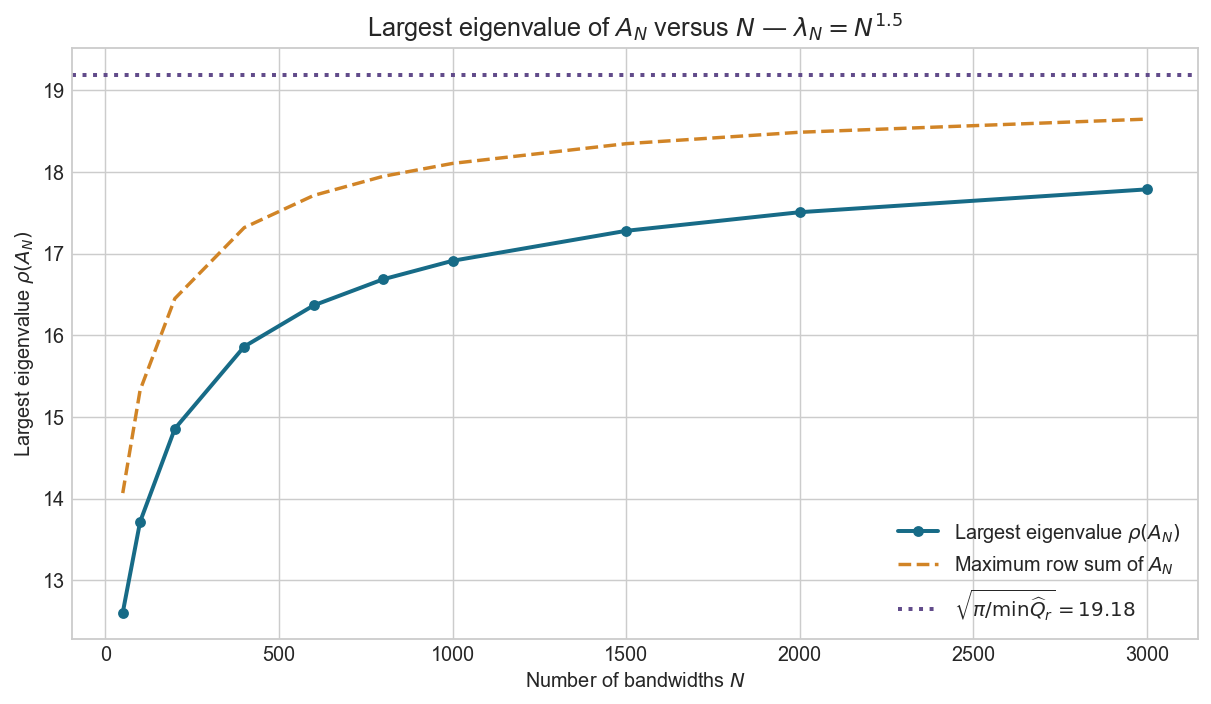

,N,lambda,max_eigenvalue,max_row_sum,scaled_max_eigenvalue,scaled_max_row_sum,lambda_over_N2
0,50,353.553391,16.142901,18.016394,12.605020,14.067917,0.141421
1,100,1000.000000,21.103877,23.583263,13.716950,15.328484,0.100000
2,200,2828.427125,27.318111,30.247583,14.855956,16.449042,0.070711
3,400,8000.000000,34.773719,37.965383,15.861847,17.317707,0.050000
4,600,14696.938457,39.739130,43.007123,16.365734,17.711589,0.040825
5,800,22627.416998,43.553671,46.844318,16.684991,17.945606,0.035355
6,1000,31622.776602,46.689306,49.980813,16.911512,18.103741,0.031623
7,1500,58094.750193,52.809050,56.068965,17.278486,18.345091,0.025820
8,2000,89442.719100,57.504921,60.720610,17.506335,18.485293,0.022361
9,3000,164316.767252,64.667149,67.793495,17.786017,18.645885,0.018257


In [6]:
fig, ax = plt.subplots(figsize=(9.2, 5.3), constrained_layout=True)
ax.plot(results["N"], results["scaled_max_eigenvalue"], "o-", color="#176B87",
        linewidth=2.2, markersize=5, label=r"Largest eigenvalue $\rho(A_N)$")
ax.plot(results["N"], results["scaled_max_row_sum"], "--", color="#D18426",
        linewidth=1.9, label=r"Maximum row sum of $A_N$")
if ADMISSIBLE_JOINT_LIMIT:
    ax.axhline(M_REFERENCE, color="#614B8A", linestyle=":", linewidth=2.2,
               label=rf"$\sqrt{{\pi/\min \widehat Q_r}}={M_REFERENCE:.4g}$")
ax.set(xlabel=r"Number of bandwidths $N$", ylabel=r"Largest eigenvalue $\rho(A_N)$",
       title=rf"Largest eigenvalue of $A_N$ versus $N$ — {LAMBDA_LABEL}")
ax.legend(loc="best")
fig.savefig(RESULTS_DIR / "rescaled_A_max_eigenvalue_vs_N.png", dpi=170)
plt.show()
plt.close(fig)
display(results[[
    "N", "lambda", "max_eigenvalue", "max_row_sum",
    "scaled_max_eigenvalue", "scaled_max_row_sum", "lambda_over_N2",
]].round(6))
if ADMISSIBLE_JOINT_LIMIT:
    print(f"At N={int(results.iloc[-1]['N'])}: scaled eigenvalue / reference = "
          f"{results.iloc[-1]['scaled_max_eigenvalue']/M_REFERENCE:.6f}.")
print(f"All figures are saved automatically under {PDF_DIR}")

**Secondary comparison: largest eigenvalue of the original matrix $S^{(N)}$.**

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/similarity_max_eigenvalue_vs_n/002_largest_similarity_eigenvalue_versus_n_lambda_n_n_1_5.pdf


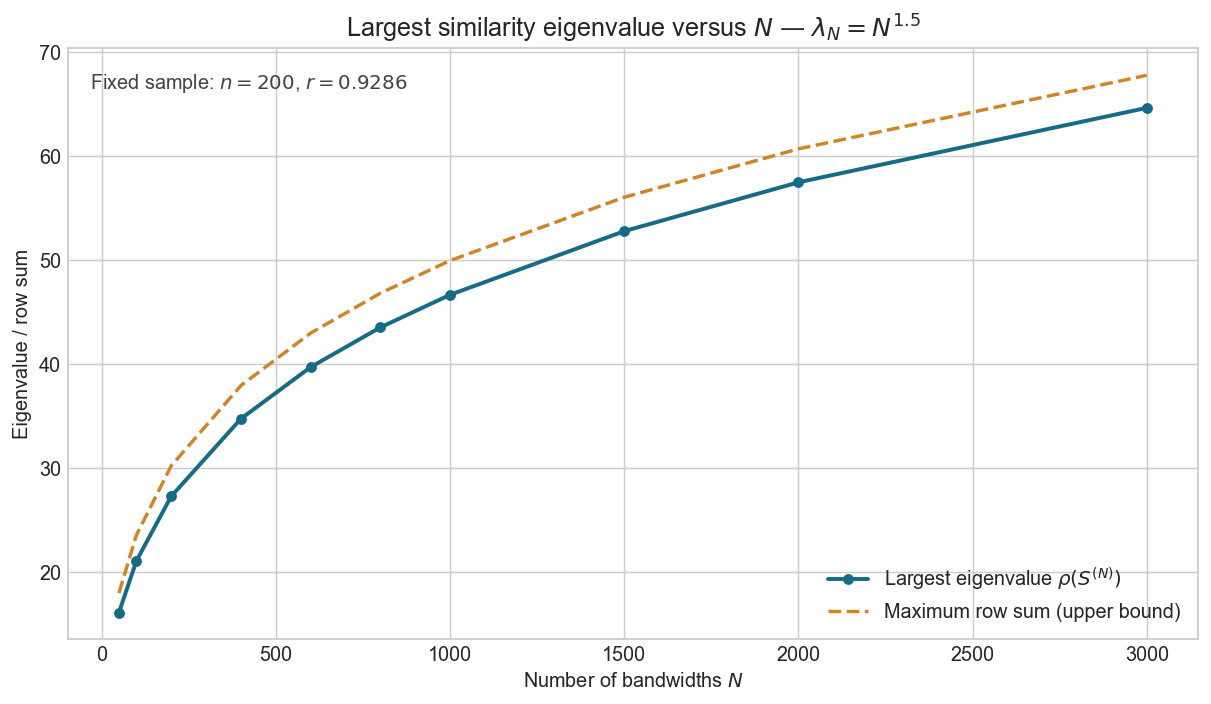

In [7]:
fig, ax = plt.subplots(figsize=(9.2, 5.3), constrained_layout=True)
ax.plot(results["N"], results["max_eigenvalue"], "o-", color="#176B87",
        linewidth=2.2, markersize=5, label=r"Largest eigenvalue $\rho(S^{(N)})$")
ax.plot(results["N"], results["max_row_sum"], "--", color="#D18426",
        linewidth=1.9, label="Maximum row sum (upper bound)")
ax.set(xlabel=r"Number of bandwidths $N$", ylabel="Eigenvalue / row sum",
       title=rf"Largest similarity eigenvalue versus $N$ — {LAMBDA_LABEL}")
ax.text(0.02, 0.96, rf"Fixed sample: $n={N_DATA}$, $r={R:.4g}$",
        transform=ax.transAxes, va="top", color="#444444")
ax.legend(loc="lower right")
fig.savefig(RESULTS_DIR / "max_eigenvalue_vs_N.png", dpi=170)
plt.show()
plt.close(fig)

**Sample energy $\hat Q_r(h)$ on $(0,2]$.**

Read the saved sample and $r$ from the eigenvalue experiment; no new observations
are drawn. Evaluate the existing analytic Gaussian energy
$$\hat Q_r(h)=\frac12 h^{2(1-r)}\|\partial_h\hat f_h\|_2^2$$
using [qr_log_energy](kde_tools/continuous_minimizers.py), as defined in the
[thesis proposition](../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex).

Both horizontal axes cover $[0,2]$. The function is defined for $h>0$; the
numerical curve starts at $h=10^{-4}$. The left panel uses a logarithmic vertical
axis to display the full computed range. The right panel uses a linear vertical
axis with its upper range clipped, to show the smaller-scale features clearly.
Detected local minima are refined numerically and compared with both endpoints
of the evaluated interval. These are numerical comparisons, not a proof of global optimality.

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/similarity_max_eigenvalue_vs_n/001_sample_energy_widehat_q_r_h_same_data_n_200_r_0_928571.pdf
Numerical interval minimum: h=2, Q_r=0.0085382919
Local minimum: h=0.56148654, Q_r=0.019292107
Source sample: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/analysis/similarity_max_eigenvalue_vs_n/fixed_sample.csv


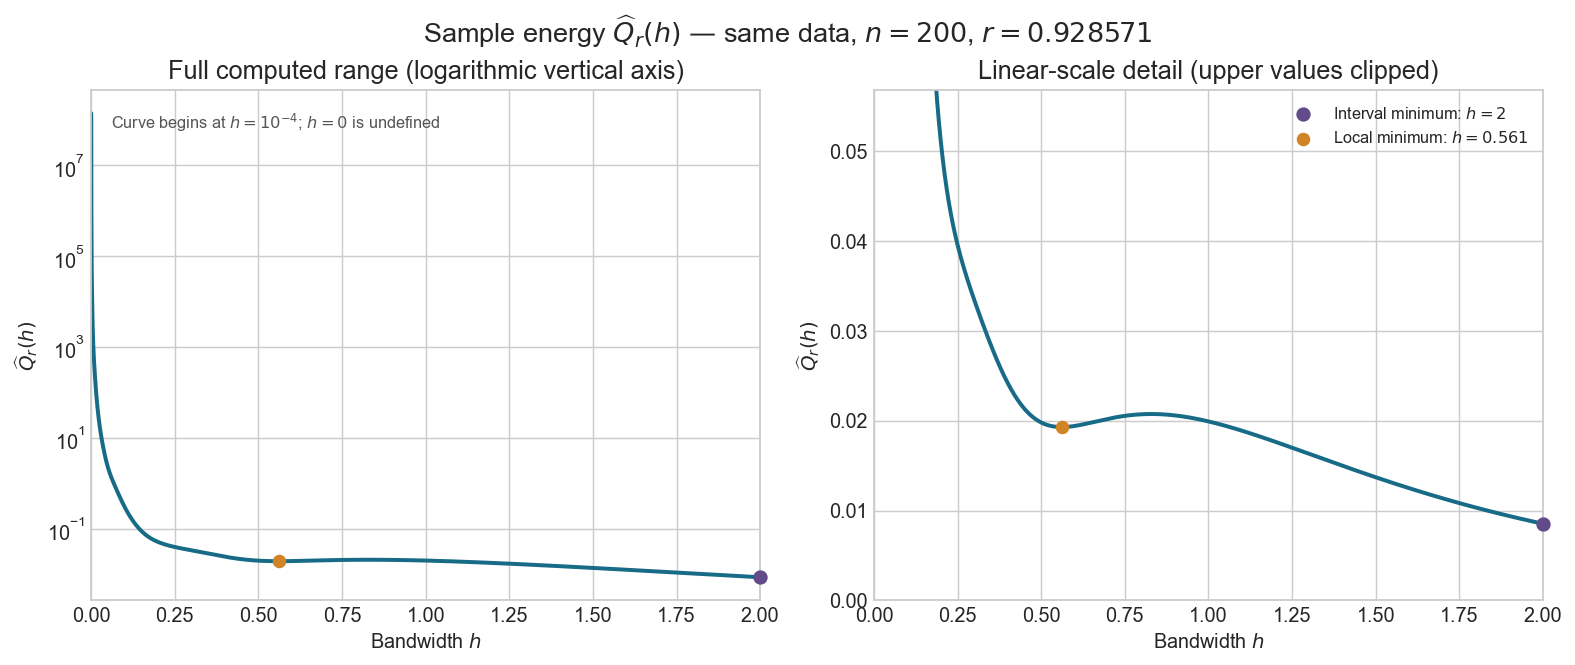

In [8]:
# Reuse the exact saved sample and settings of the eigenvalue sweep.
q_plot_settings = json.loads((RESULTS_DIR / "settings.json").read_text())
q_plot_samples = pd.read_csv(RESULTS_DIR / "fixed_sample.csv")["sample"].to_numpy()
q_plot_r = float(q_plot_settings["r"])
q_plot_n = len(q_plot_samples)
q_plot_pairs = pdist(q_plot_samples[:, None], metric="sqeuclidean")
Q_PLOT_H_MIN, Q_PLOT_H_MAX = 1e-4, 2.0

def plotted_energy(log_h):
    return float(qr_log_energy(q_plot_pairs, q_plot_n, float(log_h), q_plot_r)[0])

q_plot_h = np.unique(np.r_[
    np.geomspace(Q_PLOT_H_MIN, 0.1, 400),
    np.linspace(0.1, Q_PLOT_H_MAX, 1601),
])
q_plot_values = np.array([plotted_energy(np.log(h)) for h in q_plot_h])
if not np.all(np.isfinite(q_plot_values)) or np.any(q_plot_values <= 0):
    raise ArithmeticError("Expected positive finite sample-energy values.")

q_local_indices = np.flatnonzero(
    (q_plot_values[1:-1] < q_plot_values[:-2]) &
    (q_plot_values[1:-1] < q_plot_values[2:])
) + 1
q_local_minima = []
for index in q_local_indices:
    q_optimum = minimize_scalar(
        plotted_energy,
        bounds=(np.log(q_plot_h[index-1]), np.log(q_plot_h[index+1])),
        method="bounded", options={"xatol": 1e-12},
    )
    if not q_optimum.success:
        raise RuntimeError(q_optimum.message)
    q_local_minima.append((float(np.exp(q_optimum.x)), float(q_optimum.fun)))
q_plot_candidates = [
    (float(q_plot_h[0]), float(q_plot_values[0])),
    (float(q_plot_h[-1]), float(q_plot_values[-1])),
    *q_local_minima,
]
q_best_h, q_best_value = min(q_plot_candidates, key=lambda item: item[1])

# Confirm agreement with the reference value of the preceding eigenvalue plot.
np.testing.assert_allclose(
    plotted_energy(np.log(q_plot_settings["reference_h"])),
    q_plot_settings["reference_q_minimum"], rtol=1e-11, atol=1e-13,
)
pd.DataFrame({"h": q_plot_h, "Q_hat_r": q_plot_values}).to_csv(
    RESULTS_DIR / "qhat_r_over_0_to_2.csv", index=False
)
q_plot_summary = {
    "n": q_plot_n, "r": q_plot_r,
    "evaluated_h_min": Q_PLOT_H_MIN, "evaluated_h_max": Q_PLOT_H_MAX,
    "numerical_minimizer_h": q_best_h, "numerical_minimum_Q": q_best_value,
    "local_minima": [{"h": h, "Q": value} for h, value in q_local_minima],
}
(RESULTS_DIR / "qhat_r_over_0_to_2_summary.json").write_text(
    json.dumps(q_plot_summary, indent=2) + "\n"
)

fig, axes = plt.subplots(1, 2, figsize=(12.0, 5.0), constrained_layout=True)
fig.suptitle(
    rf"Sample energy $\widehat Q_r(h)$ — same data, $n={q_plot_n}$, $r={q_plot_r:.6g}$",
    fontsize=15,
)
for ax in axes:
    ax.plot(q_plot_h, q_plot_values, color="#176B87", linewidth=2.2)
    ax.scatter([q_best_h], [q_best_value], s=48, color="#614B8A", zorder=4,
               clip_on=False, label=rf"Interval minimum: $h={q_best_h:.3g}$")
    for number, (h_local, q_local) in enumerate(q_local_minima):
        ax.scatter([h_local], [q_local], s=42, color="#D18426", zorder=4,
                   label=rf"Local minimum: $h={h_local:.3f}$" if number == 0 else None)
    ax.set(xlim=(0, 2), xlabel=r"Bandwidth $h$", ylabel=r"$\widehat Q_r(h)$")
    ax.set_xticks(np.arange(0, 2.01, 0.25))
axes[0].set(yscale="log", title="Full computed range (logarithmic vertical axis)")
axes[0].text(0.03, 0.96, r"Curve begins at $h=10^{-4}$; $h=0$ is undefined",
             transform=axes[0].transAxes, va="top", fontsize=9, color="#555555")
q_detail_upper = 1.12 * float(np.max(q_plot_values[q_plot_h >= 0.2]))
axes[1].set(ylim=(0, q_detail_upper),
            title="Linear-scale detail (upper values clipped)")
axes[1].legend(loc="upper right", fontsize=9)
fig.savefig(RESULTS_DIR / "qhat_r_over_0_to_2.png", dpi=180)
plt.show()  # The setup cell's shared exporter also saves this figure as PDF.
plt.close(fig)
print(f"Numerical interval minimum: h={q_best_h:.8g}, Q_r={q_best_value:.8g}")
for h_local, q_local in q_local_minima:
    print(f"Local minimum: h={h_local:.8g}, Q_r={q_local:.8g}")
print(f"Source sample: {RESULTS_DIR / 'fixed_sample.csv'}")